## ML Process Implementation in Python

Import all the needed libraries and packages


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

## Data Collection

We will use the diabetes dataset available in Python. 

In [4]:
# Import the diabetes dataset from a CSV file
data = pd.read_csv("diabetes.csv")

# Confirm that the dataset has been loaded
print("Diabetes dataset successfully loaded!")

# Display the first 10 records
print("\nFIRST 10 RECORDS:")
print(data.head(10))

NameError: name 'pd' is not defined

## Exploratory Data Analysis (EDA)

We may perform data analysis to better understand the dataset

In [3]:
print("\nDATASET SIZE:")
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

print("\nCOLUMN NAMES:")
print(data.columns)

print("\nDATASET INFORMATION:")
data.info()

print("\nMISSING VALUES:")
print(data.isnull().sum())

print("\nDESCRIPTIVE STATISTICS:")
print(data.describe())

print("\nDIABETES OUTCOME:")
print(data["Outcome"].value_counts())

# Convert Glucose column into a NumPy array
glucose = np.array(data["Glucose"])

print("\nGLUCOSE ANALYSIS USING NUMPY:")

print("Mean Glucose:", np.mean(glucose))
print("Minimum Glucose:", np.min(glucose))
print("Maximum Glucose:", np.max(glucose))
print("Standard Deviation:", np.std(glucose))

# Count patients with glucose greater than 140
high_glucose = np.sum(glucose > 140)

print("Patients with Glucose > 140:", high_glucose)


DATASET SIZE:
Rows: 768
Columns: 9

COLUMN NAMES:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

MISSING VALUES:
Pre

## Some Data Visualization


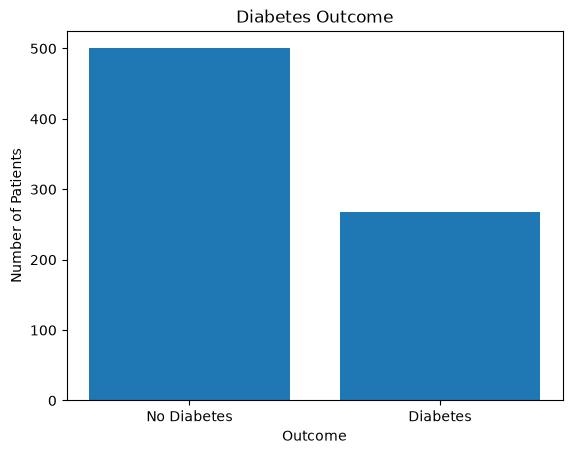

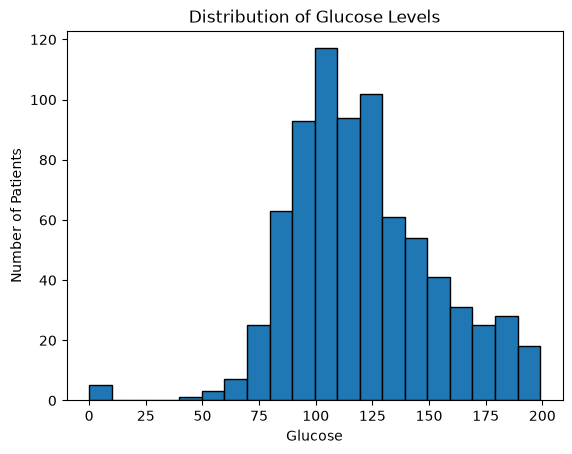

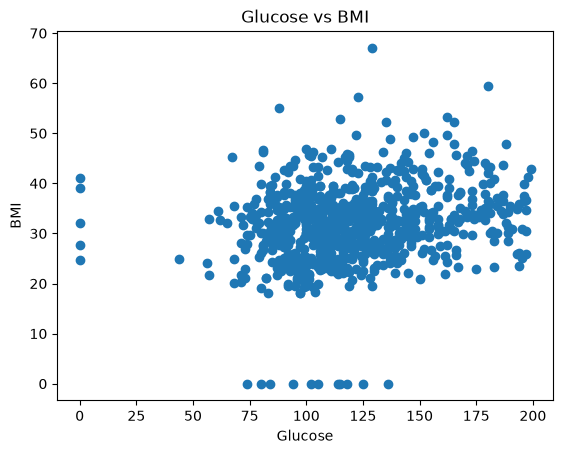

In [4]:
# 1. Bar chart - Diabetes Outcome
outcome_counts = data["Outcome"].value_counts().sort_index()

plt.bar(["No Diabetes", "Diabetes"], outcome_counts)
plt.title("Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")
plt.show()


# 2. Histogram - Glucose Distribution
plt.hist(data["Glucose"], bins=20, edgecolor="black")
plt.title("Distribution of Glucose Levels")
plt.xlabel("Glucose")
plt.ylabel("Number of Patients")
plt.show()


# 3. Scatter Plot - Glucose vs BMI
plt.scatter(data["Glucose"], data["BMI"])
plt.title("Glucose vs BMI")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.show()

## Preprocessing


In [5]:
# Separate features and target
X = data.drop("Outcome", axis=1)
y = data["Outcome"]

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

## Feature Engineering

In [6]:
# Standardize the numerical features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Training the Model

In [7]:
# Create the model
model = LogisticRegression()

# Train the model
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

## Model Evaluation

MODEL ACCURACY:
0.7532467532467533

CONFUSION MATRIX:
[[79 20]
 [18 37]]


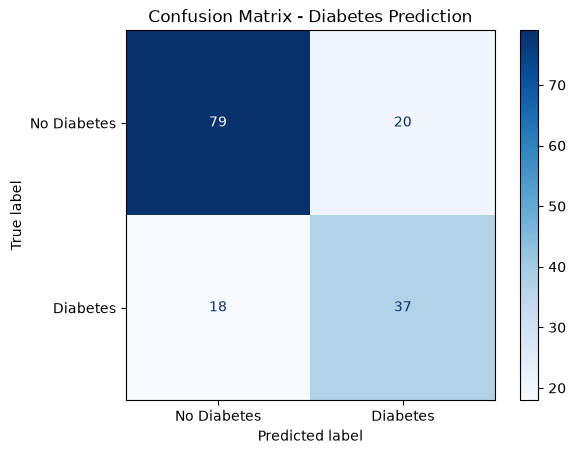

In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Make predictions using the test dataset
predictions = model.predict(X_test)

# Calculate model accuracy
accuracy = accuracy_score(y_test, predictions)

print("MODEL ACCURACY:")
print(accuracy)


# Create the confusion matrix
cm = confusion_matrix(y_test, predictions)

print("\nCONFUSION MATRIX:")
print(cm)


# Visualize the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

display.plot(cmap="Blues")

plt.title("Confusion Matrix - Diabetes Prediction")
plt.show()